# Pandas và Matplotlib

Nhóm lập trình nhận ba file: `train.csv` có điểm cuối kỳ để tham khảo, `test.csv` có những học sinh cần dự đoán, và `sample_submission.csv` cho biết cách ghi kết quả. Hai file có thể không cùng thứ tự dòng; một số ô giờ tự học bị bỏ trống; thông tin lớp nằm ở bảng khác. Câu hỏi của buổi này là: **làm sao đi từ những bảng ấy đến một file dự đoán đúng học sinh, đúng định dạng và kiểm lại được?**

NumPy giỏi tính trên mảng số đồng nhất. Dữ liệu bảng còn có tên cột, chữ, số và giá trị thiếu. pandas giữ những thông tin đó trong DataFrame; Matplotlib giúp ta nhìn một câu hỏi cụ thể về dữ liệu. Học sinh và điểm trong bài đều được sinh giả lập để luyện thao tác.

> **Sau bài này, có thể**
>
> - Đọc file CSV, kiểm tra shape, kiểu từng cột và số ô trống trước khi làm gì khác.
> - Lọc dòng, chọn cột, gộp nhóm bằng `groupby` và ghép bảng bằng `merge` mà không làm nhân bản dòng.
> - Chọn đúng loại biểu đồ cho một câu hỏi và vẽ nó không gây hiểu lầm.
> - Tạo file nộp đúng thứ tự, đúng cột, không ô trống, và tự kiểm tra trước khi nộp.

## Dữ liệu của đề

Đề minh họa là dự đoán điểm Toán cuối kỳ từ lớp, giờ tự học mỗi tuần và điểm học kỳ 1. Với mỗi dòng, `id` nhận diện học sinh; `diem_toan` là nhãn cần dự đoán; ba cột còn lại là dữ liệu đầu vào. `id` là khóa ghép bảng, chưa phải một đặc trưng có ý nghĩa về năng lực.

Ô đầu tự sinh 500 dòng bằng seed cố định: 400 dòng có nhãn và 100 dòng được che nhãn, ghi vào một thư mục tạm để chạy lại không đè lên dữ liệu thật. Ở bước này chỉ cần nhận ra tên cột và số dòng. Công thức sinh điểm chỉ để tạo dữ liệu; từ ô sau trở đi ta làm như khi nhận đề thật, chỉ biết những gì nằm trong các file.

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from tempfile import TemporaryDirectory

demo_directory = TemporaryDirectory(prefix="phase0-demo-", dir=".")
data_dir = Path(demo_directory.name)

rng = np.random.default_rng(7)
n = 500
lop = rng.choice(["10A1", "10A2", "10A3", "10A4"], size=n)
gio = rng.gamma(2.0, 3.0, n).round(1)
hk1 = np.clip(rng.normal(6.5, 1.3, n), 0, 10).round(1)
bonus = pd.Series(lop).map({"10A1": 0.6, "10A2": 0.0, "10A3": -0.3, "10A4": 0.2}).to_numpy()
toan = np.clip(0.55 * hk1 + 0.12 * gio + bonus + rng.normal(0, 0.8, n) + 2.0, 0, 10).round(2)
gio[rng.random(n) < 0.06] = np.nan                          # một số học sinh không khai giờ tự học

full = pd.DataFrame({"id": np.arange(1, n + 1), "lop": lop, "gio_tu_hoc": gio, "diem_hk1": hk1, "diem_toan": toan})
full.iloc[:400].to_csv(data_dir / "train.csv", index=False, encoding="utf-8")
full.iloc[400:].drop(columns="diem_toan").to_csv(data_dir / "test.csv", index=False, encoding="utf-8")
pd.DataFrame({"id": full["id"].iloc[400:], "diem_toan": 0.0}).to_csv(
    data_dir / "sample_submission.csv", index=False, encoding="utf-8")
pd.DataFrame({"lop": ["10A1", "10A2", "10A3", "10A4"], "chuyen": [True, False, False, False],
              "si_so": [38, 42, 45, 40]}).to_csv(
                  data_dir / "lop.csv", index=False, encoding="utf-8")

Bốn file nằm trong `data_dir`: dữ liệu có nhãn, dữ liệu cần dự đoán, mẫu nộp và bảng phụ mô tả lớp. Điểm nằm trong 0–10 là quy định của đề minh họa này; với đề khác, miền nhãn phải đọc từ đề.



## Đọc và nhìn dữ liệu

`pd.read_csv` đọc một file CSV (comma-separated values: mỗi dòng một bản ghi, các giá trị ngăn bởi dấu phẩy) thành một DataFrame: một bảng có tên cột, mỗi cột có một kiểu. Một cột lẻ là một Series. Năm việc làm ngay sau khi đọc, trước mọi phân tích:

In [ ]:
train = pd.read_csv(data_dir / "train.csv", encoding="utf-8")
test = pd.read_csv(data_dir / "test.csv", encoding="utf-8")
print(train.shape, test.shape)
print(train.head(3))

(400, 5) (100, 4)
   id   lop  gio_tu_hoc  diem_hk1  diem_toan
0   1  10A4         0.4       9.1       6.72
1   2  10A3         0.6       5.9       6.84
2   3  10A3         2.8       4.9       4.79


In [ ]:
print(train.dtypes)
print(train.isna().sum())

id              int64
lop            object
gio_tu_hoc    float64
diem_hk1      float64
diem_toan     float64
dtype: object
id             0
lop            0
gio_tu_hoc    23
diem_hk1       0
diem_toan      0
dtype: int64


`dtypes` cho biết pandas đã đọc từng cột theo kiểu nào: các cột số là `int64` hoặc `float64`, cột chữ `lop` hiện là `object` (phiên bản pandas mới có thể ghi `str`). Bảng sau cho thấy 23 giá trị giờ tự học bị thiếu, được lưu là `NaN`. Kiểm ô thiếu bằng `isna()`, không bằng `value == np.nan`: theo chuẩn số thực, `NaN` không bằng chính nó.



Sau khi nhìn kiểu và ô trống, ta kiểm hợp đồng dữ liệu. Nếu `id` có dạng `"001"`, hãy đọc bằng `dtype={"id": "string"}` để không mất số 0 đầu; ở bài này, ID là các số nguyên liên tiếp:

In [ ]:
assert train["id"].is_unique and test["id"].is_unique
assert train["diem_toan"].notna().all()
assert set(test.columns) == set(train.columns) - {"diem_toan"}
assert not set(train["id"]) & set(test["id"])
print("schema: OK", "train/test ids disjoint: OK")

schema: OK train/test ids disjoint: OK


Các kiểm tra này chỉ nói về định dạng. Chúng chưa trả lời được một học sinh có bị lặp dưới hai ID không, hay train và test có giống nhau không; bài 1.3 sẽ quay lại hai câu hỏi đó.

In [ ]:
print(train.describe().round(2))
print(train["lop"].value_counts())

           id  gio_tu_hoc  diem_hk1  diem_toan
count  400.00      377.00    400.00     400.00
mean   200.50        5.43      6.55       6.44
std    115.61        4.13      1.39       1.16
min      1.00        0.30      2.90       3.51
25%    100.75        2.60      5.60       5.64
50%    200.50        4.40      6.50       6.43
75%    300.25        6.80      7.50       7.21
max    400.00       23.00     10.00       9.94
lop
10A4    110
10A3    103
10A1     98
10A2     89
Name: count, dtype: int64


`describe` tóm tắt mọi cột số: số giá trị không trống, trung bình, độ lệch chuẩn, các phân vị. Đọc bảng này là cách nhanh nhất để phát hiện điều lạ: điểm âm, điểm trên 10, giờ tự học 100 giờ mỗi tuần. Ở đây mọi thứ hợp lý, trừ cột `gio_tu_hoc` có `count` nhỏ hơn 400 do ô trống. `value_counts` đếm số lần xuất hiện của từng giá trị trong một cột chữ.

Trung bình (mean) là tổng chia cho số lượng; trung vị (median, dòng `50%`) là giá trị đứng giữa khi xếp thứ tự; yếu vị (mode) là giá trị gặp nhiều nhất. Biết trung bình và số lượng là biết tổng: 50 giá trị có trung bình 40 thì tổng là 2000, thêm giá trị 142 thì trung bình mới là $2142/51 = 42$. Phương sai là trung bình bình phương độ lệch so với trung bình; độ lệch chuẩn (`std`) là căn của nó, cùng đơn vị với dữ liệu. Cột mà mọi giá trị bằng nhau có phương sai 0. Một giá trị nằm rất xa phần còn lại gọi là ngoại lai (outlier), có thể là lỗi nhập như chiều cao 1700 cm, có thể là trường hợp hiếm có thật. Ngoại lai kéo trung bình mạnh mà gần như không đổi trung vị: lương 8, 9, 10, 11 và 100 triệu có trung bình 27,6 nhưng trung vị 10. Với phân bố lệch phải như thu nhập hay giờ tự học, thứ tự thường gặp là trung bình > trung vị > yếu vị.



**Hỏi nhanh.** Bảng `describe` của cột `gio_tu_hoc` cho mean 5.43, median (dòng 50%) 4.40 và max 23.0. Phân bố giờ tự học nhiều khả năng có dạng nào?

- A. Lệch phải, đuôi dài phía giá trị lớn kéo mean lên
- B. Lệch trái, đuôi dài phía giá trị nhỏ kéo mean xuống
- C. Gần đối xứng, vì mean và median chỉ chênh khoảng một giờ
- D. Chưa nói được gì nếu chưa vẽ histogram

<details><summary>Đáp án</summary>

A. Lệch phải, đuôi dài phía giá trị lớn kéo mean lên

Vài giá trị rất lớn đủ kéo mean lên, còn median gần như đứng yên. Ở đây mean lớn hơn median hơn một giờ, và max 23 nằm rất xa phân vị 75% là 6.8. Đó là dấu hiệu của một đuôi dài bên phải. Với phân bố lệch như thế, điền ô thiếu bằng median an toàn hơn bằng mean, và mục Ô trống sẽ làm đúng như vậy.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 69](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=27)

</details>

## Chọn và lọc

Chọn cột bằng tên; chọn dòng bằng điều kiện. `loc` nhận nhãn dòng và tên cột, `iloc` nhận vị trí như mảng NumPy:

In [ ]:
print(train["diem_toan"].mean().round(3), train[["lop", "diem_toan"]].shape)
gioi = train[(train["diem_hk1"] >= 8) & (train["lop"] != "10A3")]
print(len(gioi), gioi["diem_toan"].mean().round(3))
print(train.loc[train["gio_tu_hoc"] > 20, ["id", "lop", "gio_tu_hoc"]])
print(train.iloc[:2, :3])

6.436 (400, 2)
52 7.416
      id   lop  gio_tu_hoc
220  221  10A3        22.6
252  253  10A1        20.1
287  288  10A4        23.0
399  400  10A3        21.7
   id   lop  gio_tu_hoc
0   1  10A4         0.4
1   2  10A3         0.6


Tên cột có dấu cách như `"total price"` chỉ chọn được bằng `df["total price"]`; cách viết `df.ten_cot` chỉ dùng khi tên cột là tên biến hợp lệ. Khi cắt dòng, `iloc[1:3]` theo vị trí và không lấy vị trí cuối như NumPy, còn `loc[20:40]` theo nhãn và lấy cả nhãn cuối.

Hai chi tiết cú pháp hay làm sai. Thứ nhất, kết hợp điều kiện dùng `&`, `|`, `~`, không dùng `and`, `or`, `not`; `and` hỏi giá trị đúng sai của cả một cột và báo lỗi. Thứ hai, mỗi điều kiện phải nằm trong ngoặc, vì `&` được ưu tiên trước `>=`.

Tạo cột mới bằng phép gán, và sắp xếp bằng `sort_values`:

In [ ]:
train["tien_bo"] = train["diem_toan"] - train["diem_hk1"]
print(train.sort_values("tien_bo", ascending=False)[["id", "diem_hk1", "diem_toan", "tien_bo"]].head(3))

      id  diem_hk1  diem_toan  tien_bo
236  237       5.3       9.35     4.05
252  253       4.9       8.23     3.33
339  340       3.9       7.22     3.32


Khi muốn **sửa** một số ô theo điều kiện, dùng một lần `loc` với cả điều kiện dòng và tên cột. Viết hai lần chọn liên tiếp (gán nối chuỗi, chained assignment) thì phép gán rơi vào một bảng tạm do lần chọn đầu tạo ra, không vào bảng gốc. Đoạn sau sửa trên một bản sao để giữ nguyên nhãn thật:

In [ ]:
demo = train.copy()
demo[demo["lop"] == "10A1"]["diem_toan"] = 0              # SAI: sửa trên bảng tạm
print((demo["diem_toan"] == 0).sum())
demo.loc[demo["lop"] == "10A1", "diem_toan"] = 0          # ĐÚNG
print((demo["diem_toan"] == 0).sum())

0
98


Dòng đầu không đổi gì trong `demo` (pandas chỉ in một cảnh báo, không dừng chương trình); dòng sau đổi đúng 98 học sinh lớp 10A1. Bài học rút ra: sau phép gán, in lại giá trị để kiểm, đừng coi việc chương trình không báo lỗi là bằng chứng đã sửa xong.



**Hỏi nhanh.** Cần lọc các học sinh lớp 10A1 có điểm HK1 dưới 5. Viết thế nào cho đúng?

- A. `train[train["lop"] == "10A1" and train["diem_hk1"] < 5]`
- B. `train[train["lop"] == "10A1" & train["diem_hk1"] < 5]`
- C. `train.loc["10A1", "diem_hk1" < 5]`
- D. `train[(train["lop"] == "10A1") & (train["diem_hk1"] < 5)]`

<details><summary>Đáp án</summary>

D. `train[(train["lop"] == "10A1") & (train["diem_hk1"] < 5)]`

`and` cần mỗi vế là một giá trị đúng hoặc sai, mà ở đây mỗi vế là cả một cột, nên báo lỗi. Nếu thiếu ngoặc, `&` được tính trước `==` và `<`, cũng báo lỗi. Vì thế mỗi điều kiện phải nằm trong một cặp ngoặc riêng. Còn `train.loc["10A1", ...]` đi tìm dòng có **nhãn index** là `"10A1"`, chứ không lọc theo cột `lop`.

</details>

## Ô trống

Một ô trống không đồng nghĩa với số 0: “không khai giờ tự học” khác “không tự học”. Vì vậy trước hết cần biết vì sao ô bị thiếu rồi mới chọn cách xử lý. pandas có sẵn `dropna()` bỏ dòng hay cột có ô trống, `fillna(...)` điền một giá trị, `interpolate()` nội suy từ các giá trị xung quanh. Một số mô hình tự xử lý được giá trị thiếu, số khác cần điền trước. Ở đây ta điền bằng trung vị (median) cùng lớp, và dùng trung vị chung khi gặp lớp chưa có trong train. Cách này có tốt hơn điền một trung vị chung hay không thì phải so bằng validation, việc của chương sau.

In [ ]:
med_all = train["gio_tu_hoc"].median()
med_lop = train.groupby("lop")["gio_tu_hoc"].median()
print(round(med_all, 2), med_lop.round(2).to_dict())

def fill_hours(table):
    result = table.copy()
    group_value = result["lop"].map(med_lop)
    result["gio_tu_hoc"] = result["gio_tu_hoc"].fillna(group_value).fillna(med_all)
    return result

train = fill_hours(train)
test = fill_hours(test)
print(train["gio_tu_hoc"].isna().sum(), test["gio_tu_hoc"].isna().sum())
unseen = pd.DataFrame({"lop": ["10A5"], "gio_tu_hoc": [np.nan]})
print(fill_hours(unseen)["gio_tu_hoc"].tolist())

4.4 {'10A1': 4.2, '10A2': 4.4, '10A3': 4.7, '10A4': 4.45}
0 0
[4.4]


Đọc ba phần output: trung vị chung 4.4, không còn ô thiếu trong hai bảng, và lớp mới 10A5 nhận 4.4 nhờ bước dự phòng. `map` tra trung vị của mỗi lớp; khóa không có cho giá trị thiếu. Nếu cả cột train không có dữ liệu thì trung vị chung cũng thiếu, phải có quy tắc khác thay vì tiếp tục huấn luyện.



Các trung vị được tính **chỉ từ dữ liệu dùng để fit**, rồi giữ cố định khi biến đổi dữ liệu cần dự đoán. Ở bài này đó là train. Sau này khi tách validation khỏi train, phải tính chúng trên phần train còn lại, không trên cả hai phần. Quy trình này giúp đánh giá phản ánh việc gặp dữ liệu mới, thay vì lén dùng thống kê của dữ liệu đang chấm.

**Hỏi nhanh.** Trên train, median giờ học của lớp A là 2, của lớp B là 4, của cả bảng là 3. Tức là `med_by_class = {"A": 2, "B": 4}` và `med_all = 3`. Ở test có một học sinh lớp C bị thiếu giờ học. Sau `test["lop"].map(med_by_class).fillna(med_all)`, ô của bạn ấy được điền số mấy?

- A. 3
- B. 4
- C. 0
- D. 2

<details><summary>Đáp án</summary>

A. 3

Lớp C không có trong `med_by_class`, nên `map` trả về một ô thiếu. `fillna` điền vào đó median chung là 3, tính trên train. 2 và 4 là median của hai lớp khác. Điền 0 là biến “không biết” thành “không học giờ nào”.

</details>

## groupby

`groupby` chia bảng thành từng nhóm theo giá trị của một cột, tính trên từng nhóm, rồi ghép kết quả lại. Đây là phép `GROUP BY` của SQL, và là công cụ dùng nhiều nhất khi tìm hiểu dữ liệu.

In [ ]:
print(train.groupby("lop")["diem_toan"].agg(["mean", "std", "count"]).round(2))

      mean   std  count
lop                    
10A1  6.79  1.00     98
10A2  6.41  1.17     89
10A3  5.96  1.14    103
10A4  6.58  1.16    110


Trong dữ liệu giả lập này, 10A1 có trung bình 6.79, 10A3 có trung bình 5.96; chênh khoảng 0.83 điểm. `count` nói có bao nhiêu giá trị không thiếu dùng để tính từng nhóm, còn `std` mô tả độ phân tán. Chênh lệch trung bình gợi một giả thuyết để thử bằng validation, không chứng minh lớp học là nguyên nhân gây điểm cao.

Có hai cách lấy kết quả theo nhóm. `agg` trả về một dòng cho mỗi nhóm, như bảng trên. `transform` trả về một giá trị cho mỗi dòng của bảng gốc, giữ nguyên số dòng, nên gán thẳng thành cột mới được:

In [ ]:
agg = train.groupby("lop")["diem_toan"].mean()
tf = train.groupby("lop")["diem_toan"].transform("mean")
print(agg.shape, tf.shape)
train["toan_tb_lop"] = tf
print(train[["lop", "diem_toan", "toan_tb_lop"]].head(3).round(2))

(4,) (400,)
    lop  diem_toan  toan_tb_lop
0  10A4       6.72         6.58
1  10A3       6.84         5.96
2  10A3       4.79         5.96


Cột `toan_tb_lop` đang dùng để đọc bảng: mỗi dòng nhận trung bình của nhóm tương ứng. Vì nó tính từ **nhãn**, ta không đưa cột ấy vào đặc trưng của mô hình trong bài. Làm target encoding cho mô hình cần cách tính tránh để nhãn của dòng hoặc validation lọt vào chính đặc trưng của dòng ấy; bài 2.11 (Feature engineering) sẽ xử lý kỹ.



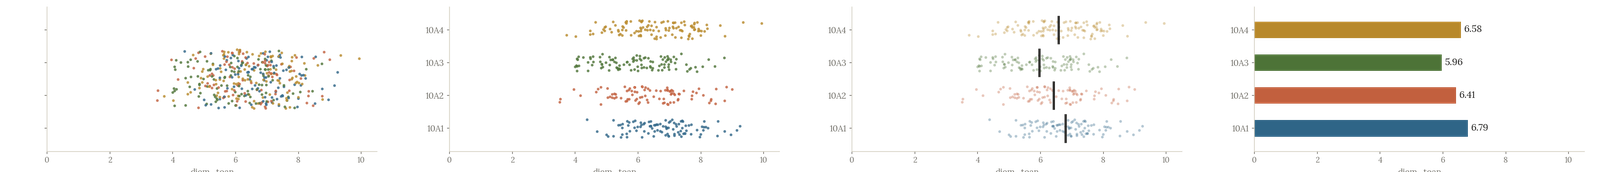

pandas còn có một điểm khác NumPy: Series thường được ghép theo **nhãn index**, không theo vị trí. Index là nhãn dòng của bảng, có thể khác cột `id`. Ví dụ sau cố ý đảo thứ tự các nhãn:

In [ ]:
tiny = pd.DataFrame({"id": [101, 102, 103]}, index=[10, 20, 30])
values = pd.Series([6.0, 7.0, 8.0], index=[30, 10, 20])
tiny["score"] = values
print(tiny["score"].tolist())

[7.0, 8.0, 6.0]


Dòng index 10 lấy 7.0, không lấy giá trị đầu 6.0. Điều này hữu ích khi các nhãn có nghĩa, nhưng dễ làm ghép sai nếu ta tưởng là gán theo vị trí. Với ID bài thi, cách rõ ràng nhất là ghép theo cột khóa bằng `merge` ở mục tiếp theo.



**Hỏi nhanh.** `train` có 400 dòng, chia thành 4 lớp. `train.groupby("lop")["diem_toan"].transform("max")` có bao nhiêu phần tử?

- A. 4
- B. 1
- C. 1600
- D. 400

<details><summary>Đáp án</summary>

D. 400

`transform` trả về một giá trị cho mỗi dòng của bảng gốc: dòng nào cũng nhận điểm cao nhất của lớp mình. Vì vậy kết quả vẫn đủ 400 phần tử và gắn được thành một cột mới. Muốn mỗi lớp gộp lại thành một số, tức 4 giá trị, thì dùng `agg("max")`.

</details>

## merge

Thông tin về lớp (lớp chuyên hay không, sĩ số) nằm ở file khác. `merge` ghép hai bảng theo một cột khóa, giống `JOIN` của SQL:

In [ ]:
lop_info = pd.read_csv(data_dir / "lop.csv", encoding="utf-8")
merged = train.merge(lop_info, on="lop", how="left", validate="many_to_one")
assert len(merged) == len(train)
print(train.shape, merged.shape)
print(merged.groupby("chuyen")["diem_toan"].mean().round(2))

(400, 7) (400, 9)
chuyen
False    6.32
True     6.79
Name: diem_toan, dtype: float64


Ghép xong, số dòng phải giữ nguyên: mỗi học sinh khớp đúng một lớp. Điều đó chỉ đúng khi khóa ở bảng phụ không bị trùng. Nếu file lớp vô tình có một dòng lặp, `merge` sẽ nhân đôi mọi học sinh của lớp đó mà không báo gì:

In [ ]:
dup = pd.concat([lop_info, lop_info.iloc[[0]]])          # 10A1 xuất hiện hai lần
print(train.merge(dup, on="lop", how="left").shape)
try:
    train.merge(dup, on="lop", how="left", validate="many_to_one")
except pd.errors.MergeError as e:
    print("MergeError:", str(e).splitlines()[0])

(498, 9)
MergeError: Merge keys are not unique in right dataset; not a many-to-one merge


Tham số `validate="many_to_one"` khẳng định “nhiều học sinh ứng với một lớp”, và báo lỗi ngay nếu điều đó sai. Luôn dùng nó, hoặc ít nhất in shape trước và sau khi ghép. Một bảng train bị nhân bản dòng sẽ làm mọi con số về sau sai theo.



`how="left"` giữ mọi dòng của bảng bên trái, kể cả dòng không khớp được (khi đó các cột mới là `NaN`). `how="inner"` chỉ giữ dòng khớp được ở cả hai bên, và có thể làm mất mẫu một cách âm thầm.

**Hỏi nhanh.** Bảng trái có ba học sinh, thuộc các lớp A, A, B. Bảng phải có ba dòng thông tin lớp, cũng là A, A, B, nghĩa là lớp A bị lặp. Ghép hai bảng bằng `merge` với `how="left"` theo cột lớp thì được bao nhiêu dòng?

- A. 3
- B. 4
- C. 5
- D. 9

<details><summary>Đáp án</summary>

C. 5

Mỗi học sinh lớp A khớp với cả hai dòng A bên phải, còn học sinh lớp B khớp một dòng, nên có $2\cdot 2 + 1 = 5$ dòng. `how="left"` giữ mọi dòng bên trái, nhưng không hứa giữ nguyên số dòng. Khóa nào bị lặp ở bảng phải thì dòng bên trái sẽ bị nhân lên.

</details>

## Vẽ biểu đồ trả lời một câu hỏi

Một biểu đồ tốt trả lời một câu hỏi cụ thể. Chọn loại biểu đồ theo câu hỏi, không theo thói quen:

| Câu hỏi | Biểu đồ | Matplotlib |
|---|---|---|
| Một biến phân bố thế nào? | Histogram | `ax.hist` |
| Hai biến số có liên quan không? | Scatter | `ax.scatter` |
| So sánh giá trị giữa các nhóm | Bar | `ax.bar` |
| Một đại lượng thay đổi theo thời gian | Line | `ax.plot` |

Matplotlib có hai cách viết; nên dùng cách hướng đối tượng: tạo `fig` (cả hình) và `ax` (từng ô vẽ), rồi gọi phương thức trên `ax`.

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.hist(train["diem_toan"], bins=20)
ax1.set_xlabel("điểm Toán cuối kỳ")
ax1.set_ylabel("số học sinh")
ax2.scatter(train["gio_tu_hoc"], train["diem_toan"], s=10, alpha=0.6)
ax2.set_xlabel("giờ tự học mỗi tuần")
ax2.set_ylabel("điểm Toán cuối kỳ")
fig.tight_layout()
fig.savefig(data_dir / "eda.png", dpi=120)
plt.show()
plt.close(fig)
print(train[["gio_tu_hoc", "diem_hk1", "diem_toan"]].corr().round(2))

            gio_tu_hoc  diem_hk1  diem_toan
gio_tu_hoc        1.00      0.00       0.36
diem_hk1          0.00      1.00       0.56
diem_toan         0.36      0.56       1.00




Histogram cho thấy điểm tập trung quanh 6–7, không thấy điểm ngoài miền 0–10. Scatter có xu hướng đi lên nhưng các điểm tản rộng: giờ tự học chỉ gắn với một phần biến thiên của nhãn trong dữ liệu này. Bảng hệ số tương quan (correlation) cho 0.56 với điểm HK1 và 0.36 với giờ tự học; hai đặc trưng có tương quan tuyến tính gần 0. Hệ số này không phải “số điểm tăng mỗi giờ” hay tỉ lệ học sinh, và không chứng minh nhân quả. Hệ số tương quan nằm trong $[-1, 1]$: gần 1 là hai biến cùng tăng, gần $-1$ là biến này tăng thì biến kia giảm, gần 0 là không có quan hệ tuyến tính. Hai biến đi cùng nhau có thể do một nguyên nhân chung: ngày nóng bán được nhiều kem và cũng nhiều người đi bơi, nhưng ăn kem không làm người ta đi bơi.

Giờ tự học đã được điền thiếu, nên 23 điểm trên scatter là giá trị điền chứ không phải quan sát thật; biểu đồ phản ánh cả lựa chọn tiền xử lý. Khi xem dữ liệu thật, kiểm thêm số ô thiếu, số mẫu từng nhóm và các điểm bất thường trước khi giải thích một xu hướng.

Biểu đồ hộp (boxplot) tóm tắt một biến theo nhóm: vạch giữa hộp là trung vị, hộp chứa một nửa số giá trị ở khoảng giữa, hai râu kéo ra phần còn lại, chấm rời là ngoại lai; nhờ vậy dễ so nhiều lớp cạnh nhau.

Biểu đồ cột có một cái bẫy hay gặp: trục tung không bắt đầu từ 0. Chiều cao cột là thứ mắt người so sánh, nên cắt trục sẽ phóng đại khác biệt:



Mọi biểu đồ nộp kèm bài hay đưa vào báo cáo cần có nhãn trục kèm đơn vị, và trục tung của biểu đồ cột bắt đầu từ 0.

**Hỏi nhanh.** Muốn xem điểm HK1 có liên quan đến điểm Toán cuối kỳ không, ta nên vẽ biểu đồ gì?

- A. Histogram điểm Toán, tô màu theo mức điểm HK1
- B. Scatter, mỗi học sinh là một điểm (HK1, Toán)
- C. Biểu đồ cột điểm Toán trung bình của từng lớp
- D. Đường nối điểm Toán của các học sinh theo `id`

<details><summary>Đáp án</summary>

B. Scatter, mỗi học sinh là một điểm (HK1, Toán)

Muốn xem hai biến số đi cùng nhau ra sao thì vẽ scatter: mỗi chấm là một học sinh, giữ nguyên cặp (HK1, Toán) của bạn ấy. Histogram tô màu chỉ cho thấy phân bố của từng nhóm, còn từng cặp giá trị thì mất. Biểu đồ cột theo lớp trả lời một câu hỏi khác. Nối điểm theo `id` thì vô nghĩa, vì `id` không phải thứ tự thời gian.

</details>

## Tạo file nộp

Baseline đơn giản nhất có dùng dữ liệu: dự đoán cho mỗi học sinh test điểm Toán trung bình của lớp mình trong tập train, lớp mới thì nhận trung bình chung. Baseline này chủ yếu để kiểm đường đi từ dữ liệu tới file nộp; nó tốt đến đâu thì chương sau mới đo. Bảng dự đoán được cố ý đảo ngược thứ tự: nếu ghép đúng theo ID, file nộp vẫn phải đúng thứ tự mẫu.

In [ ]:
mean_by_lop = train.groupby("lop")["diem_toan"].mean()
pred_table = test[["id", "lop"]].iloc[::-1].copy()
pred_table["diem_toan"] = pred_table["lop"].map(mean_by_lop).fillna(train["diem_toan"].mean())

sample = pd.read_csv(data_dir / "sample_submission.csv", encoding="utf-8")
sub = sample[["id"]].merge(
    pred_table[["id", "diem_toan"]], on="id", how="left", validate="one_to_one")
assert sub.shape == sample.shape, sub.shape
assert list(sub.columns) == list(sample.columns)
assert sub["id"].equals(sample["id"])
assert np.isfinite(sub["diem_toan"].to_numpy()).all()
assert sub["diem_toan"].between(0, 10).all()
sub.to_csv(data_dir / "submission.csv", index=False, encoding="utf-8")
read_back = pd.read_csv(data_dir / "submission.csv", encoding="utf-8")
assert read_back.columns.tolist() == sample.columns.tolist()
assert read_back["id"].equals(sample["id"])
assert np.isfinite(read_back["diem_toan"].to_numpy()).all()
print(read_back.head(3).round(3))
print("file:", read_back.shape, "OK")

    id  diem_toan
0  401      5.964
1  402      6.579
2  403      6.414
file: (100, 2) OK


Nhìn ba ID đầu: 401, 402, 403 đúng thứ tự mẫu, dù bảng dự đoán đang đảo ngược.

**Hỏi nhanh.** `pred_table` đang xếp ID theo thứ tự 500, 499, …, 401, còn `sample` xếp 401, 402, …, 500. Chạy `sub = sample[["id"]].merge(pred_table, on="id", how="left")`. ID trong `sub` theo thứ tự nào?

- A. 500, 499, …, 401, theo bảng dự đoán
- B. 401, 402, …, 500, theo bảng bên trái
- C. Tăng dần, vì `merge` luôn sắp theo khóa
- D. Không biết trước, phải tự `sort_values` sau đó

<details><summary>Đáp án</summary>

B. 401, 402, …, 500, theo bảng bên trái

Với `how="left"`, pandas giữ thứ tự dòng của bảng bên trái. Đặt `sample` bên trái thì file nộp tự theo đúng khung của đề, dù bảng dự đoán bị xáo thế nào. Dòng `assert sub["id"].equals(sample["id"])` trong code kiểm lại đúng điều này.

</details>

Các kiểm tra giữ số dòng, tên và thứ tự cột, thứ tự ID, dự đoán hữu hạn và miền 0–10 của đề minh họa. `notna()` không bắt được vô cùng, nên ta dùng `np.isfinite`. Đọc lại CSV kiểm cả tệp đã ghi, không chỉ bảng trong bộ nhớ. Máy chấm của mỗi đề có thể đòi thêm điều kiện khác; danh sách kiểm phải theo đúng đề.



Tham số `index=False` cũng cần được kiểm bằng một phản ví dụ:

In [ ]:
sub.to_csv(data_dir / "submission_bad.csv", encoding="utf-8")  # quên index=False
print(pd.read_csv(data_dir / "submission_bad.csv").columns.tolist())

['Unnamed: 0', 'id', 'diem_toan']


Thiếu `index=False`, pandas ghi thêm một cột chỉ số không tên ở đầu file. Máy chấm sẽ thấy ba cột thay vì hai và từ chối bài, hoặc tệ hơn, đọc nhầm cột.

Baseline này tốt đến đâu thì phải đo trên dữ liệu có đáp án, bằng cách để riêng một phần tập train. Đó là nội dung của bài 1.1 và 1.3.

Kiểm xong thì dọn thư mục tạm. Khi chạy bài thật, chỉ dọn dữ liệu tạo để thử; giữ dữ liệu đề và file cần nộp:

In [ ]:
demo_directory.cleanup()
print(data_dir.exists())

False


## Ngày giờ, chuỗi và dữ liệu không phải bảng

Cột thời gian thường là chuỗi, mã học sinh có thể lẫn khoảng trắng và chữ hoa thường. Đề ảnh, văn bản, âm thanh thì cho một thư mục tệp kèm bảng nhãn.

In [ ]:
log = pd.DataFrame({"thoi_diem": ["2026-03-02 07:45", "2026-03-02 21:10", "2026-03-07 09:30"],
                    "ma_hs": [" hs001", "HS002 ", "hs003"]})
log["thoi_diem"] = pd.to_datetime(log["thoi_diem"], format="%Y-%m-%d %H:%M")
log["gio"] = log["thoi_diem"].dt.hour
log["thu"] = log["thoi_diem"].dt.dayofweek          # 0 là thứ Hai, 6 là Chủ nhật
log["ma_hs"] = log["ma_hs"].str.strip().str.upper()
print(log)
print(log["thoi_diem"].max() - log["thoi_diem"].min())

            thoi_diem  ma_hs  gio  thu
0 2026-03-02 07:45:00  HS001    7    0
1 2026-03-02 21:10:00  HS002   21    0
2 2026-03-07 09:30:00  HS003    9    5
5 days 01:45:00


Ghi rõ `format` cho `pd.to_datetime`, vì `03-02` có thể là ngày 3 tháng 2 hoặc ngày 2 tháng 3. `.dt` lấy giờ, thứ, tháng; hiệu hai thời điểm là một khoảng thời gian. `.str` xử lý chuỗi trên cả cột: chưa chuẩn hóa thì `" hs001"` và `"HS001"` là hai mã khác nhau, và `merge` theo mã sẽ bỏ sót dòng. Cột giá ghi `"1.200.000 đ"` cũng là chuỗi nên `mean()` báo lỗi; `.str.replace(r"\D", "", regex=True)` bỏ mọi ký tự không phải chữ số, rồi `.astype(int)` đổi thành 1200000.

Với thư mục ảnh và tệp nhãn, đọc ảnh **theo thứ tự của bảng nhãn** để ảnh thứ $i$ đi với nhãn thứ $i$:

In [ ]:
from PIL import Image

with TemporaryDirectory() as directory:
    root = Path(directory)
    (root / "images").mkdir()
    for name, value in [("c.png", 120), ("a.png", 40), ("b.png", 200)]:
        Image.new("L", (4, 3), color=value).save(root / "images" / name)   # ảnh xám rộng 4, cao 3
    pd.DataFrame({"file": ["a.png", "b.png", "c.png"], "label": ["toi", "sang", "vua"]}).to_csv(
        root / "labels.csv", index=False)

    labels = pd.read_csv(root / "labels.csv")
    images = [np.asarray(Image.open(root / "images" / name).convert("L")) for name in labels["file"]]
    X = np.stack(images).astype(np.float32) / 255
    print(X.shape, X.dtype, X.mean(axis=(1, 2)).round(3))
    print(labels["label"].tolist())

(3, 3, 4) float32 [0.157 0.784 0.471]
['toi', 'sang', 'vua']




PIL ghi kích thước theo (rộng, cao), NumPy theo (hàng, cột): ảnh rộng 4, cao 3 thành mảng $(3, 4)$, ba ảnh thành $(3, 3, 4)$. Độ sáng 0.157 là $40/255$, đúng ảnh tối của nhãn `toi`. Ảnh màu thì dùng `.convert("RGB")`, để ảnh có kênh trong suốt hay ảnh xám không làm lệch số kênh.

**Hỏi nhanh.** Đọc ảnh bằng `sorted(Path("images").iterdir())` rồi ghép với cột `label` của `labels.csv` theo vị trí. Vì sao cách này nguy hiểm?

- A. `iterdir` chỉ đọc được tối đa 1000 tệp
- B. Ảnh đọc theo cách này luôn thành ảnh xám
- C. Thứ tự tên tệp sau khi sắp chưa chắc trùng thứ tự dòng trong `labels.csv`
- D. `sorted` làm đổi tên tệp trên đĩa

<details><summary>Đáp án</summary>

C. Thứ tự tên tệp sau khi sắp chưa chắc trùng thứ tự dòng trong `labels.csv`

`labels.csv` có thể xếp theo nhãn hay theo thời gian chụp, và `img10.png` đứng trước `img2.png` khi sắp theo chữ. Model vẫn học, không báo lỗi, nhưng học nhãn sai. Đọc ảnh theo cột tên tệp của bảng nhãn thì không lệch được.

</details>

Văn bản hay ở dạng JSON Lines, mỗi dòng một đối tượng JSON. Âm thanh thường là WAV: một dãy số nguyên kèm tần số lấy mẫu.

In [ ]:
import json, wave

with TemporaryDirectory() as directory:
    root = Path(directory)
    rows = [{"id": 1, "text": "Học máy", "tags": ["ai"]}, {"id": 2, "text": "Dữ liệu bảng", "tags": []}]
    (root / "train.jsonl").write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in rows), encoding="utf-8")
    print(pd.read_json(root / "train.jsonl", lines=True))

    rate = 8000
    t = np.arange(rate // 10) / rate                       # 0,1 giây
    tone = (0.5 * np.sin(2 * np.pi * 440 * t) * 32767).astype(np.int16)
    with wave.open(str(root / "tone.wav"), "wb") as f:
        f.setnchannels(1)
        f.setsampwidth(2)                                  # 2 byte = int16
        f.setframerate(rate)
        f.writeframes(tone.tobytes())
    with wave.open(str(root / "tone.wav"), "rb") as f:
        audio = np.frombuffer(f.readframes(f.getnframes()), dtype=np.int16)
        print(f.getframerate(), audio.shape, audio.dtype, round(float(np.abs(audio).max()) / 32768, 3))

   id          text  tags
0   1       Học máy  [ai]
1   2  Dữ liệu bảng    []
8000 (800,) int16 0.5


Cột `tags` giữ list trong từng ô. Tệp WAV có 8000 mẫu mỗi giây nên 0,1 giây là 800 số `int16`; chia cho 32768 được biên độ trong $[-1, 1]$. Luôn in tần số lấy mẫu: hai tệp khác tần số thì 800 mẫu không còn cùng một khoảng thời gian.


Bảng nhỏ gồm sáu học sinh: lớp `A` có điểm $6, 8, 7$; lớp `B` có điểm $5, \text{NaN}, 9$.

1. `df.groupby("lop")["diem"].mean()`: lớp A là $(6 + 8 + 7)/3 = 7$; lớp B bỏ qua `NaN`, được $(5 + 9)/2 = 7$. Hai giá trị.
2. `df.groupby("lop")["diem"].transform("max")`: sáu giá trị $8, 8, 8, 9, 9, 9$.
3. `df["diem"].fillna(df["diem"].median())`: trung vị của năm số $5, 6, 7, 8, 9$ là $7$, nên ô trống thành $7$.
4. Ghép bảng sáu học sinh với bảng lớp có `A` xuất hiện hai lần, `how="left"`: ba học sinh lớp A mỗi người thành hai dòng, ba học sinh lớp B giữ nguyên, tổng cộng $3 \cdot 2 + 3 = 9$ dòng.
5. Với cột `float64` chứa `np.nan`, `(df["diem"] >= 7).mean()` có tỉ lệ $3/6=0.5$: phép so sánh cho `False` tại ô thiếu. Nếu hỏi “trong những học sinh đã có điểm”, cần bỏ thiếu trước, khi đó $3/5=0.6$. Hai con số trả lời hai câu hỏi khác nhau.

Đối chiếu tính tay trên cùng bảng nhỏ, với dtype được chỉ rõ:

In [ ]:
hand = pd.DataFrame({
    "lop": ["A", "A", "A", "B", "B", "B"],
    "diem": pd.Series([6, 8, 7, 5, np.nan, 9], dtype="float64"),
})
print(hand.groupby("lop")["diem"].mean().to_dict())
print(hand.groupby("lop")["diem"].transform("max").tolist())
print((hand["diem"] >= 7).mean(), (hand["diem"].dropna() >= 7).mean())
print(hand.groupby("lop")["diem"].agg(["count", "size"]).to_dict())

{'A': 7.0, 'B': 7.0}
[8.0, 8.0, 8.0, 9.0, 9.0, 9.0]
0.5 0.6
{'count': {'A': 3, 'B': 2}, 'size': {'A': 3, 'B': 3}}


`count` bỏ ô thiếu của cột đang xét, `size` đếm mọi dòng nhóm. Hai kết quả trả lời hai câu hỏi khác nhau; lựa chọn mẫu số phải theo mục đích phân tích.

## Bẫy cài đặt

**Cột số bị đọc thành chữ.** Một ô ghi `"?"` hoặc `"không rõ"` có thể làm cả cột được đọc thành chữ. Kiểm tra `dtypes`; `pd.to_numeric(df[col], errors="coerce")` đổi ô không hợp lệ thành thiếu. Phải đếm và xem những ô bị đổi, vì một lỗi định dạng hàng loạt không nên bị che bằng cách điền thiếu. `read_csv(..., na_values=["?"])` phù hợp khi đề đã xác định `?` là ký hiệu thiếu.

**Sửa qua hai lần chọn.** `df[mask]["col"] = v` không sửa gì. Dùng `df.loc[mask, "col"] = v`.

**`merge` nhân bản dòng.** Luôn `validate=` hoặc so shape trước và sau.

**Quên `index=False`.** File nộp có thêm cột không tên.

**Tính thống kê trên test.** Trung vị, trung bình dùng để điền ô trống hay chuẩn hóa phải tính từ train.

**Đọc sai định dạng.** File dùng dấu `;` hoặc dấu phẩy thập phân có thể cần `read_csv(..., sep=";", decimal=",")`. Tiếng Việt viết `1.500` là một nghìn năm trăm và `1,5` là một phẩy năm, tiếng Anh thì ngược lại, nên số phải chuẩn hóa theo ngôn ngữ của nguồn. Nếu đề mô tả nhiều cột mà bảng chỉ có một cột, kiểm dòng đầu và dấu phân cách. Một CSV hợp lệ vẫn có thể chỉ có một cột, nên shape cần được so với hợp đồng của file.

## Khi đi thi

- **Năm dòng đầu tiên** sau khi đọc: `shape`, `head()`, `dtypes`, `isna().sum()`, `describe()`. Làm cho cả train và test, và so xem hai tập có khác nhau không.
- **Vẽ phân bố của nhãn** trước khi chọn metric và mô hình: lệch lớp, giá trị ngoại lai, nhãn bị làm tròn.
- **Ghép theo khóa có `validate`**, in shape trước và sau mỗi lần ghép.
- **Tạo file nộp từ `sample_submission`**, ghép theo `id`, kiểm hữu hạn, tên cột, số dòng và miền giá trị nếu đề yêu cầu; đọc lại sau `to_csv(index=False)`.
- **Chuẩn bị baseline sớm** để bắt lỗi định dạng trước khi tốn thời gian vào mô hình. Thời điểm nộp và số lượt được phép phải theo điều kiện cuộc thi cụ thể.

## Tóm tắt

- DataFrame là bảng có tên cột, mỗi cột một kiểu; đọc bằng `read_csv`, kiểm tra ngay `shape`, `dtypes`, `isna().sum()`, `describe()`.
- Lọc bằng điều kiện trong ngoặc nối bởi `&`, `|`, `~`; sửa ô bằng một lần `loc[mask, col]`.
- `groupby` + `agg` cho một dòng mỗi nhóm; `transform` cho một giá trị mỗi dòng gốc.
- `merge` theo khóa với `validate=` để kiểm quan hệ ghép; `left` vẫn có thể nhân dòng nếu khóa phải bị trùng.
- Chọn biểu đồ theo câu hỏi; ghi nhãn trục; trục cột bắt đầu từ 0.
- File nộp: lấy khung từ `sample_submission`, ghép theo `id`, kiểm tra, `index=False`.

## Kiểm tra cuối bài

Mười câu dưới đây bao quát cả bài. Làm hết rồi xem điểm; câu nào sai thì đọc lại mục tương ứng.

**Câu 1.** Vừa đọc xong `train.csv`. Việc đầu tiên nên làm là gì?

- A. Xem `shape`, `dtypes`, `isna().sum()` và `describe()`
- B. Huấn luyện ngay một mô hình nhỏ để có điểm so sánh
- C. Xóa mọi dòng có ô trống cho bảng sạch
- D. Vẽ biểu đồ đường của từng cột theo thứ tự dòng

<details><summary>Đáp án</summary>

A. Xem `shape`, `dtypes`, `isna().sum()` và `describe()`

Bốn lệnh này cho ta biết bảng to cỡ nào, cột nào bị đọc sai kiểu, ô trống nằm ở đâu, và giá trị có hợp lý không. Huấn luyện mô hình trên một cột bị đọc sai kiểu chỉ cho ra một con số vô nghĩa. Xóa dòng trống khi chưa biết có bao nhiêu dòng như thế có thể làm mất phần lớn dữ liệu. Thứ tự dòng trong file thường tùy ý, nên vẽ đường theo dòng không nói lên điều gì.

</details>
**Câu 2.** Cột `tuoi` có một ô ghi `"không rõ"`. Sau `read_csv`, cột này có kiểu gì?

- A. `int64`
- B. `float64`, ô `"không rõ"` tự thành `NaN`
- C. Kiểu chữ (`object` hoặc `str`)
- D. `bool`

<details><summary>Đáp án</summary>

C. Kiểu chữ (`object` hoặc `str`)

Chỉ cần một ô không đọc được thành số là pandas để cả cột ở dạng chữ. Khi đó mọi phép tính trên cột sẽ sai hoặc báo lỗi. Cách sửa là `pd.to_numeric(df["tuoi"], errors="coerce")`: ô nào không đổi được sang số thì thành `NaN`.

</details>
**Câu 3.** Bảng có sáu dòng, cột `diem` kiểu `float64` gồm các giá trị 5, 6, 7, 8, 9 và `np.nan`. `df["diem"].mean()` và `(df["diem"] >= 7).mean()` lần lượt bằng bao nhiêu?

- A. $5.83$ và $0.6$
- B. $7$ và $0.6$
- C. $7$ và $0.5$
- D. `NaN` và `NaN`

<details><summary>Đáp án</summary>

C. $7$ và $0.5$

`mean()` của một cột bỏ qua `NaN`, nên lấy $35/5 = 7$. Ra $5.83$ là chia nhầm cho cả 6 dòng. Còn `NaN >= 7` cho `False`, nên cột `bool` có 3 giá trị `True` trên 6 dòng, tỉ lệ là $3/6 = 0.5$.

</details>
**Câu 4.** Cần cho mọi học sinh lớp A trong `df` điểm 10. Dòng nào gán thẳng vào bảng gốc, không mắc bẫy gán nối chuỗi?

- A. `df.loc[:, "diem"] = 10`
- B. `df[df["lop"] == "A"]["diem"] = 10`
- C. `df.loc[df["lop"] == "A", "diem"] = 10`
- D. `df["diem"].iloc[:] = 10`

<details><summary>Đáp án</summary>

C. `df.loc[df["lop"] == "A", "diem"] = 10`

`df.loc[điều kiện dòng, cột]` chọn đúng các ô cần sửa trong một lần gán. `df[df["lop"] == "A"]["diem"] = 10` là gán nối chuỗi: lần lọc đầu tạo ra một bảng tạm, ta sửa bảng tạm ấy rồi nó bị bỏ đi, còn `df` không đổi. Hai phương án còn lại sửa mọi dòng, kể cả học sinh ngoài lớp A.

</details>
**Câu 5.** Cột giờ học trên train là `[1, 3, 5]`, trên test là `[2, NaN, 100]`. Ta điền ô thiếu bằng median của train. Ô `NaN` ở test được điền số mấy?

- A. 51
- B. 3
- C. 2
- D. 5

<details><summary>Đáp án</summary>

B. 3

Median của `[1, 3, 5]` là 3, nên ô thiếu ở test được điền 3. 51 là median của hai giá trị đã biết trên test, tức là lấy số liệu của test để xử lý chính test, việc ta không được làm. Giá trị 100 ở test cũng không được dùng để tính lại gì cả.

</details>
**Câu 6.** Bảng `df` có một cột tên `"diem toan"`, có dấu cách ở giữa. Ta chọn cột này thế nào?

- A. `df.diem toan`
- B. `df("diem toan")`
- C. `df.loc["diem toan"]`
- D. `df["diem toan"]`

<details><summary>Đáp án</summary>

D. `df["diem toan"]`

Cách viết `df.ten_cot` chỉ dùng được khi tên cột là một tên biến Python hợp lệ, mà tên có dấu cách thì không. `df(...)` gọi DataFrame như gọi hàm nên báo lỗi. `df.loc["diem toan"]` lại đi tìm một **dòng** có nhãn ấy. Ngoặc vuông với chuỗi thì luôn chọn được cột, nên cứ dùng cách này làm mặc định.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 110](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=43)

</details>
**Câu 7.** `train` có 400 dòng. Ghép thêm thông tin lớp bằng `train.merge(info, on="lop", how="left")` thì thành 437 dòng. Nhiều khả năng là do đâu?

- A. Một số lớp xuất hiện nhiều lần trong `info`
- B. `how="left"` luôn thêm dòng cho khớp đủ hai bảng
- C. Có học sinh không khớp lớp nào nên sinh dòng `NaN`
- D. `merge` tạo thêm dòng khi sắp xếp lại theo khóa

<details><summary>Đáp án</summary>

A. Một số lớp xuất hiện nhiều lần trong `info`

Lớp nào bị lặp trong `info` thì mỗi học sinh lớp ấy khớp với nhiều dòng, nên bảng dài ra. Học sinh không khớp lớp nào chỉ nhận `NaN`, không sinh thêm dòng. Sắp xếp cũng chỉ đổi thứ tự. Thêm `validate="many_to_one"` vào `merge` thì pandas báo lỗi ngay khi gặp chuyện này.

</details>
**Câu 8.** Điểm trung bình của bốn trường là 7.1, 7.2, 7.3 và 7.4. Muốn người xem thấy đúng các trường chênh nhau nhiều hay ít, ta nên vẽ thế nào?

- A. Histogram của bốn điểm để xem trường nào cao nhất
- B. Biểu đồ cột bắt đầu từ 0, ghi giá trị trên mỗi cột
- C. Biểu đồ cột bắt đầu từ 7.0, không ghi chú gì
- D. Đường nối bốn trường theo tên, đọc như xu hướng theo thời gian

<details><summary>Đáp án</summary>

B. Biểu đồ cột bắt đầu từ 0, ghi giá trị trên mỗi cột

Cột bắt đầu từ 0 thì chiều cao tỉ lệ đúng với giá trị, nên người xem thấy bốn trường gần như ngang nhau. Ghi số trên mỗi cột thì vẫn đọc được chênh lệch 0.1. Nếu trục bắt đầu từ 7.0 mà không ghi chú, cột 7.4 trông cao gấp bốn cột 7.1. Histogram dùng để xem phân bố của nhiều giá trị. Tên trường cũng không phải thời gian để nối thành đường.

</details>
**Câu 9.** Hệ số tương quan giữa giờ tự học và điểm Toán là $0.36$. Con số này nói lên điều gì?

- A. Tự học thêm một giờ thì điểm tăng khoảng 0.36
- B. Tự học nhiều là nguyên nhân làm điểm cao
- C. Khoảng 36% học sinh tự học nhiều có điểm cao
- D. Hai biến cùng tăng theo đường thẳng, ở mức vừa phải

<details><summary>Đáp án</summary>

D. Hai biến cùng tăng theo đường thẳng, ở mức vừa phải

Hệ số tương quan cho biết hai biến cùng tăng giảm theo một đường thẳng chặt đến đâu. 0.36 nghĩa là cùng chiều, ở mức vừa phải. Nó không phải số điểm tăng thêm mỗi giờ, không phải tỉ lệ học sinh, và không chứng minh tự học là nguyên nhân làm điểm cao.

</details>
**Câu 10.** Đọc lại file CSV sắp nộp, ta thấy thừa một cột `Unnamed: 0`, còn cột `id` và cột dự đoán vẫn đúng. Cột thừa là index của pandas bị ghi ra. Sửa bước ghi file thế nào?

- A. Gọi `reset_index()` rồi ghi như cũ
- B. Ghi với `index=False`, rồi đọc lại để kiểm
- C. Sắp xếp theo dự đoán trước khi ghi để bỏ index
- D. Đọc file lên rồi đổi tên `Unnamed: 0` thành `id`

<details><summary>Đáp án</summary>

B. Ghi với `index=False`, rồi đọc lại để kiểm

`to_csv` mặc định ghi cả index thành một cột không tên, còn `index=False` thì bỏ cột ấy đi. Gọi `reset_index()` rồi ghi như cũ vẫn ra thêm một cột index mới. Sắp xếp không bỏ được index. Đổi tên `Unnamed: 0` thành `id` thì file có hai cột cùng tên. Ghi xong, nên đọc lại để kiểm cả tên cột lẫn thứ tự ID.

</details>
## Đọc thêm

- pandas — [*10 minutes to pandas*](https://pandas.pydata.org/docs/user_guide/10min.html). Hướng dẫn chính thức, đi qua đúng các thao tác của bài: đọc, chọn, lọc, gộp nhóm, ghép bảng.
- McKinney — [*Python for Data Analysis*, 3rd edition](https://wesmckinney.com/book/). Sách miễn phí của chính tác giả pandas; chương 5, 7, 8, 10 bổ sung cho bài này.
- VanderPlas — [*Python Data Science Handbook*](https://jakevdp.github.io/PythonDataScienceHandbook/), chương 3 và 4. pandas và Matplotlib với nhiều ví dụ ngắn chạy được.
- Wilke — [*Fundamentals of Data Visualization*](https://clauswilke.com/dataviz/). Sách miễn phí về chọn biểu đồ cho đúng câu hỏi và tránh biểu đồ gây hiểu lầm, như cắt trục ở biểu đồ cột.
- Matplotlib — [*Quick start guide*](https://matplotlib.org/stable/users/explain/quick_start.html). Cách viết `fig, ax`, các loại biểu đồ cơ bản và cách lưu hình.
- Kaggle Learn — [*Pandas*](https://www.kaggle.com/learn/pandas). Khóa ngắn có bài tập thao tác bảng trong notebook để luyện thêm công cụ.
- pandas — [*Merge, join, concatenate and compare*](https://pandas.pydata.org/docs/user_guide/merging.html) và [*Copy-on-Write*](https://pandas.pydata.org/docs/user_guide/copy_on_write.html). Đọc quan hệ one-to-one/many-to-one và cách cập nhật bảng qua một lần `loc`.
- pandas — [*Working with missing data*](https://pandas.pydata.org/docs/user_guide/missing_data.html). Đọc sự khác nhau giữa `NaN`, `pd.NA`, `count`, `size` và các phép gộp có bỏ qua giá trị thiếu.